In [39]:
%load_ext autoreload
%autoreload 2
import cv2 as cv
import numpy as np
from matplotlib import pyplot as plt
from collections import deque
from datetime import datetime


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


### Check if it manages to load video

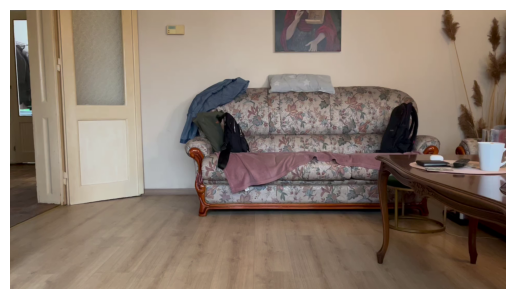

In [40]:
cap = cv.VideoCapture("test2.mov")

if not cap.isOpened():
    print("Error opening video")

# read the first frame if there is a frame ret = true
ret, frame = cap.read()

if ret:
    frame_rgb = cv.cvtColor(frame, cv.COLOR_BGR2RGB)

    plt.imshow(frame_rgb)
    plt.axis("off")
    plt.show()



    

### ROI definition

In [41]:
def roi(frame):
    pts = np.array([
        [355, 153],   # Top left
        [1578, 113],  # Top right
        [1621, 1020], # Bottom right
        [322, 1013]   # Bottom left
    ])

    # Needed for OpenCV to understand coordinates as a list
    pts = pts.reshape((-1, 1, 2))

    # Makes black and white mask:
    mask = np.zeros(frame.shape, dtype = np.uint8)
    cv.fillPoly(mask, [pts], (255,255,255))

    # Black = delete video pixels of original frame; White = let pixels through
    rect_img = cv.bitwise_and(frame, mask)

    return rect_img



### MOG2 definition

In [42]:
def mog2(frame, fgbg_mog2):
    fgmask = fgbg_mog2.apply(frame)

    # Size of the filter
    # TODO: adjust kernel in real world situation
    kernel = np.ones((5,5), np.uint8)

    fgmask_erode = cv.erode(fgmask, kernel, iterations = 1)
    fgmask_final = cv.dilate(fgmask_erode, kernel, iterations = 1)

    return fgmask_final

### Object detection

In [43]:
def object_detect(mask, color_frame):
    contours, hierarchy = cv.findContours(mask, cv.RETR_TREE, cv.CHAIN_APPROX_NONE)
    detected = False

    for contour in contours:
        area = cv.contourArea(contour)

        #TODO: adjust in real world situation
        # If object bigger than 50 pixels
        if area > 50:
            detected = True
            cv.drawContours(color_frame, [contour], -1, (0, 255, 0), 2)

    return detected, color_frame


### Generate unique filename with a timestamp

In [44]:
def generate_timestamp():
    timestamp_str = datetime.now().strftime("%Y-%m-%d_%H-%M-%S")
    return f"event_{timestamp_str}.mp4"

### Initialize and return a new OpenCV VideoWriter

In [45]:
def start_video_writer(filename, fourcc, fps, dimensions):
    return cv.VideoWriter(filename, fourcc, fps, dimensions)

### Handling of processed video

In [46]:
def process_finished_video(filename):
    try:
        print(f"[{filename}] Video finalized and ready to send.")
        
        # TODO: Send notification thread here
    except Exception as e:
        print(f"Processing failed for {filename}: {e}")

### Main logic

In [ ]:
pre_roll_buffer = deque(maxlen=100)
filter_buffer = deque()

# for MOG2 background subtraction
fgbg_mog2 = cv.createBackgroundSubtractorMOG2(history=500, varThreshold=100, detectShadows=False)
# VideoWriter needs exact width, height and FPS to create a valid video
width = int(cap.get(cv.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv.CAP_PROP_FRAME_HEIGHT))
fps = cap.get(cv.CAP_PROP_FPS)

#fourcc - four character code: used to identify which codec program should use to shirnk the file
fourcc = cv.VideoWriter_fourcc(*'mp4v')

# Filtered video to check if it's working correctly
out_filter = cv.VideoWriter("out_filter.mp4", fourcc, fps, (width, height), isColor=False)

print("Starting video feed...")

object_detected = False
is_recording = False
out = None
frame_count = 0
frames_since_last_detection = 0
current_filename = "" 
dimensions = (width, height)


while cap.isOpened():
    ret, frame = cap.read()
    if not ret:
        break

    # Checking that MOG2 stabilized, stops counting after so the counter doesn't run to infinity
    if frame_count < 50:
        frame_count += 1 
    
    rect_image = roi(frame)
        

    # MOG2 logic
    final_mask = mog2(rect_image, fgbg_mog2)
    out_filter.write(final_mask)
    
    # Run the detection
    object_detected, tracked_frame = object_detect(final_mask, frame)


    # Recording 60 frames after detecting
    if object_detected:
        #In case of two objects being thrown closely after one another, make two videos
        if is_recording and frames_since_last_detection > 15:
            print(f"Rapid second throw! Cutting from {current_filename}...")
            out.release()

            process_finished_video(current_filename)

            current_filename = generate_timestamp()
            out = start_video_writer(current_filename, fourcc, fps, dimensions)
            
        frames_since_last_detection = 0 

    elif is_recording:
        frames_since_last_detection += 1 

   # If not recording frames go to the buffer, if it is recording they go to hard drive
    if not is_recording:
        pre_roll_buffer.append(tracked_frame)
        
    else:
        out.write(tracked_frame)

    # Trigger the "alarm", object has been detectet 
    # Frame count > 30 to give MOG2 time to stabalize
    if object_detected and frame_count > 30 and not is_recording: 
        is_recording = True 
        current_filename = generate_timestamp()

        print(f"Object detected! Triggering recording to {current_filename}")

        out = start_video_writer(current_filename, fourcc, fps, dimensions)
       
        for buffered_frame in pre_roll_buffer:
            out.write(buffered_frame)
            
        pre_roll_buffer.clear()

    # Stoping the alarm 
    if is_recording and frames_since_last_detection > 60:
        is_recording = False
        # out.release so it can be sent as a video
        out.release() 
        out = None 
        frames_since_last_detection = 0

        #TODO: notification feature here
        # Use threads so that camera doesn't freeze
        process_finished_video(current_filename)

# Only for PC similuation, real camera feed won't get here on normal run
if out is not None:
    out.release()
    print("Color video saved as 'out.mp4'.")

out_filter.release()
cap.release() 
print("Finished completely. Exiting...")

Starting video feed...
Object detected! Triggering recording to event_2026-11-03_15-36-59.mp4
[event_2026-11-03_15-36-59.mp4] Video finalized and ready to send.
Object detected! Triggering recording to event_2026-11-03_15-37-09.mp4
[event_2026-11-03_15-37-09.mp4] Video finalized and ready to send.
Object detected! Triggering recording to event_2026-11-03_15-37-22.mp4
[event_2026-11-03_15-37-22.mp4] Video finalized and ready to send.
Finished completely. Exiting...
